# Hard magnet tutorial

## Introduction

- In this notebook we explore hard magnet properties such as Hc as function of temperature for Fe16N2.
- We query databases to get temperature-dependent inputs for micromagnetic simulations from DFT and spin dynamics simulations
- We run hysteresis simulations and compute derived quantities.

Requirements:
- Software: `mammos`, `esys-escript`
- Basic understanding of [mammos-units](https://mammos-project.github.io/mammos/examples/mammos-units/quickstart.html) and [mammos-entity](https://mammos-project.github.io/mammos/examples/mammos-entity/quickstart.html)

The MODA diagram is provided at the bottom of the notebook.

In [1]:
%config InlineBackend.figure_format = "retina"

import math

import mammos_analysis
import mammos_dft
import mammos_entity as me
import mammos_spindynamics
import mammos_units as u
import matplotlib.pyplot as plt
import micromagneticmodel as mm
import numpy as np
import pyvista as pv
from matplotlib import colormaps

import tommos_adapter as ta

In [2]:
# Allow convenient conversions between A/m and T
u.set_enabled_equivalencies(u.magnetic_flux_field());

## DFT data: magnetization and anisotropy at zero Kelvin
The first step loads spontaneous magnetization `Ms_0` and the uniaxial anisotropy constant `K1_0` from a database of DFT calculations (at T=0K).

We can use the `print_info` flag to trigger printing of crystallographic information.

In [3]:
material = "Fe2.33Ta0.67Y"

results_dft = mammos_dft.db.get_micromagnetic_properties(material, print_info=True)

Found material in database.

Chemical Formula: Fe2.33Ta0.67Y
Space group name: 
Space group number: 0
Cell length a: 5.227483 Angstrom
Cell length b: 5.227483 Angstrom
Cell length c: 25.022642 Angstrom
Cell angle alpha: 90.0 deg
Cell angle beta: 90.0 deg
Cell angle gamma: 120.0 deg
Cell volume: 592.173679 Angstrom3
ICSD_label: 
OQMD_label:

In [4]:
results_dft

MicromagneticProperties(Ms_0=Entity(ontology_label='SpontaneousMagnetization', value=612746.0, unit='A / m'), Ku_0=Entity(ontology_label='UniaxialAnisotropyConstant', value=2170000.0, unit='J / m3'))

In [5]:
results_dft.Ms_0

Entity(ontology_label='SpontaneousMagnetization', value=612746.0, unit='A / m')

In [6]:
results_dft.Ku_0

Entity(ontology_label='UniaxialAnisotropyConstant', value=2170000.0, unit='J / m3')

## Temperature-dependent magnetization data from spindynamics database lookup
In the second step we use a spin dynamics calculation database to load data for the temperature-dependent magnetization.

In [7]:
results_spindynamics = mammos_spindynamics.db.get_spontaneous_magnetization(material)

We can visualize the pre-computed data using `.plot`.

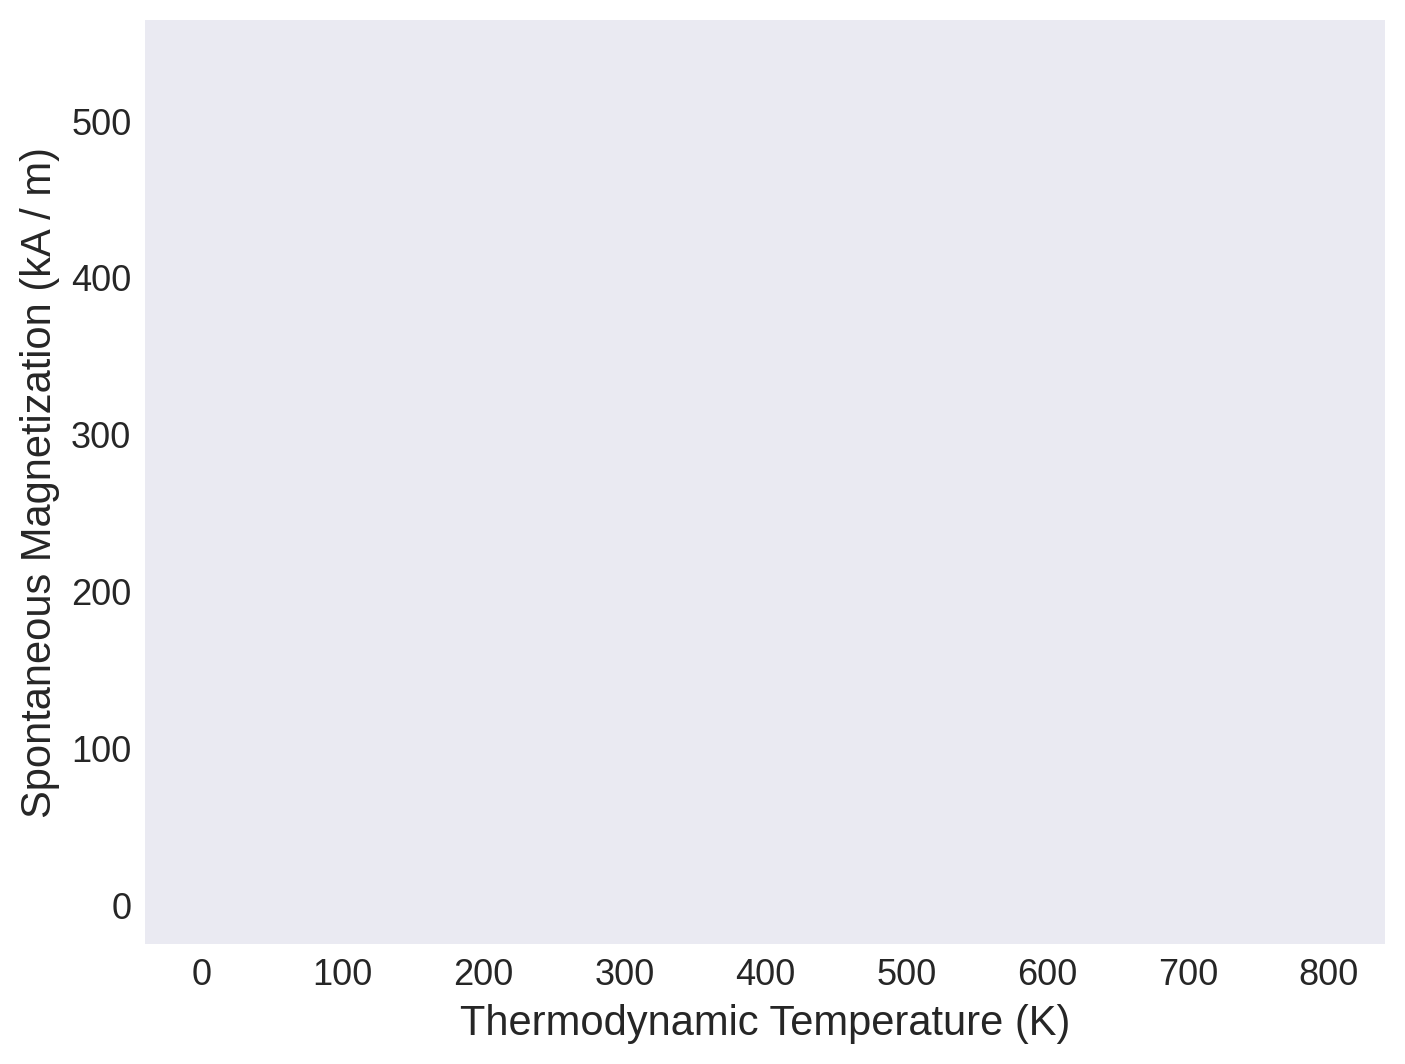

In [8]:
results_spindynamics.plot();

We can access `T` and `Ms` and get `mammos_entity.Entity` objects:

In [9]:
results_spindynamics.T

Entity(ontology_label='ThermodynamicTemperature', value=array([  0.,  10.,  20.,  40.,  60.,  80., 100., 120., 140., 160., 180.,
       200., 220., 240., 260., 280., 300., 320., 340., 360., 380., 400.,
       420., 440., 460., 480., 500., 520., 525., 530., 535., 540., 560.,
       580., 600., 620., 640., 660., 680., 700., 720., 740., 760., 780.,
       800.]), unit='K')

In [10]:
results_spindynamics.Ms

Entity(ontology_label='SpontaneousMagnetization', value=array([537.69407444, 534.21010153, 530.76436753, 523.25014179,
       515.73821821, 508.25887022, 500.54039671, 492.13118265,
       483.75561632, 474.76662259, 465.11579689, 454.00477917,
       445.20747657, 435.9139003 , 425.91795755, 414.30225011,
       402.86923234, 388.78720606, 379.37938009, 361.08960761,
       346.18346011, 331.51212323, 309.32538618, 289.79102668,
       267.5673475 , 244.08728601, 203.11783041, 154.86746066,
       128.5319578 , 123.41379485,  69.79521779,  38.60654427,
         8.52781909,   5.67183537,   4.5456332 ,   3.69262584,
         3.23444053,   2.93970208,   2.71010548,   2.57155219,
         2.3322868 ,   2.28983246,   2.16204657,   2.06734541,
         2.00064899]), unit='kA / m')

We can get also the data in the form of a `pandas.DataFrame`, which only contains the values in SI units:

In [11]:
results_spindynamics.dataframe.head()

,T,Ms
0,0.0,537.694074
1,10.0,534.210102
2,20.0,530.764368
3,40.0,523.250142
4,60.0,515.738218


## Calculate micromagnetic intrinsic properties using Kuz’min formula

- We use Kuz’min equations to compute Ms(T), A(T), K1(T)
- Kuz’min, M.D., Skokov, K.P., Diop, L.B. et al. Exchange stiffness of ferromagnets. Eur. Phys. J. Plus 135, 301 (2020). https://doi.org/10.1140/epjp/s13360-020-00294-y
- Additional details about inputs and outputs are available in the [API reference](https://mammos-project.github.io/mammos/api/mammos_analysis.kuzmin.html#mammos_analysis.kuzmin.kuzmin_formula)

In [12]:
results_kuzmin = mammos_analysis.kuzmin_properties(
    T=results_spindynamics.T,
    Ms=results_spindynamics.Ms,
    K1_0=results_dft.Ku_0,
)

The `plot` method of the returned object can be used to visualize temperature-dependence of all three quantities. The temperature range matches that of the fit data:

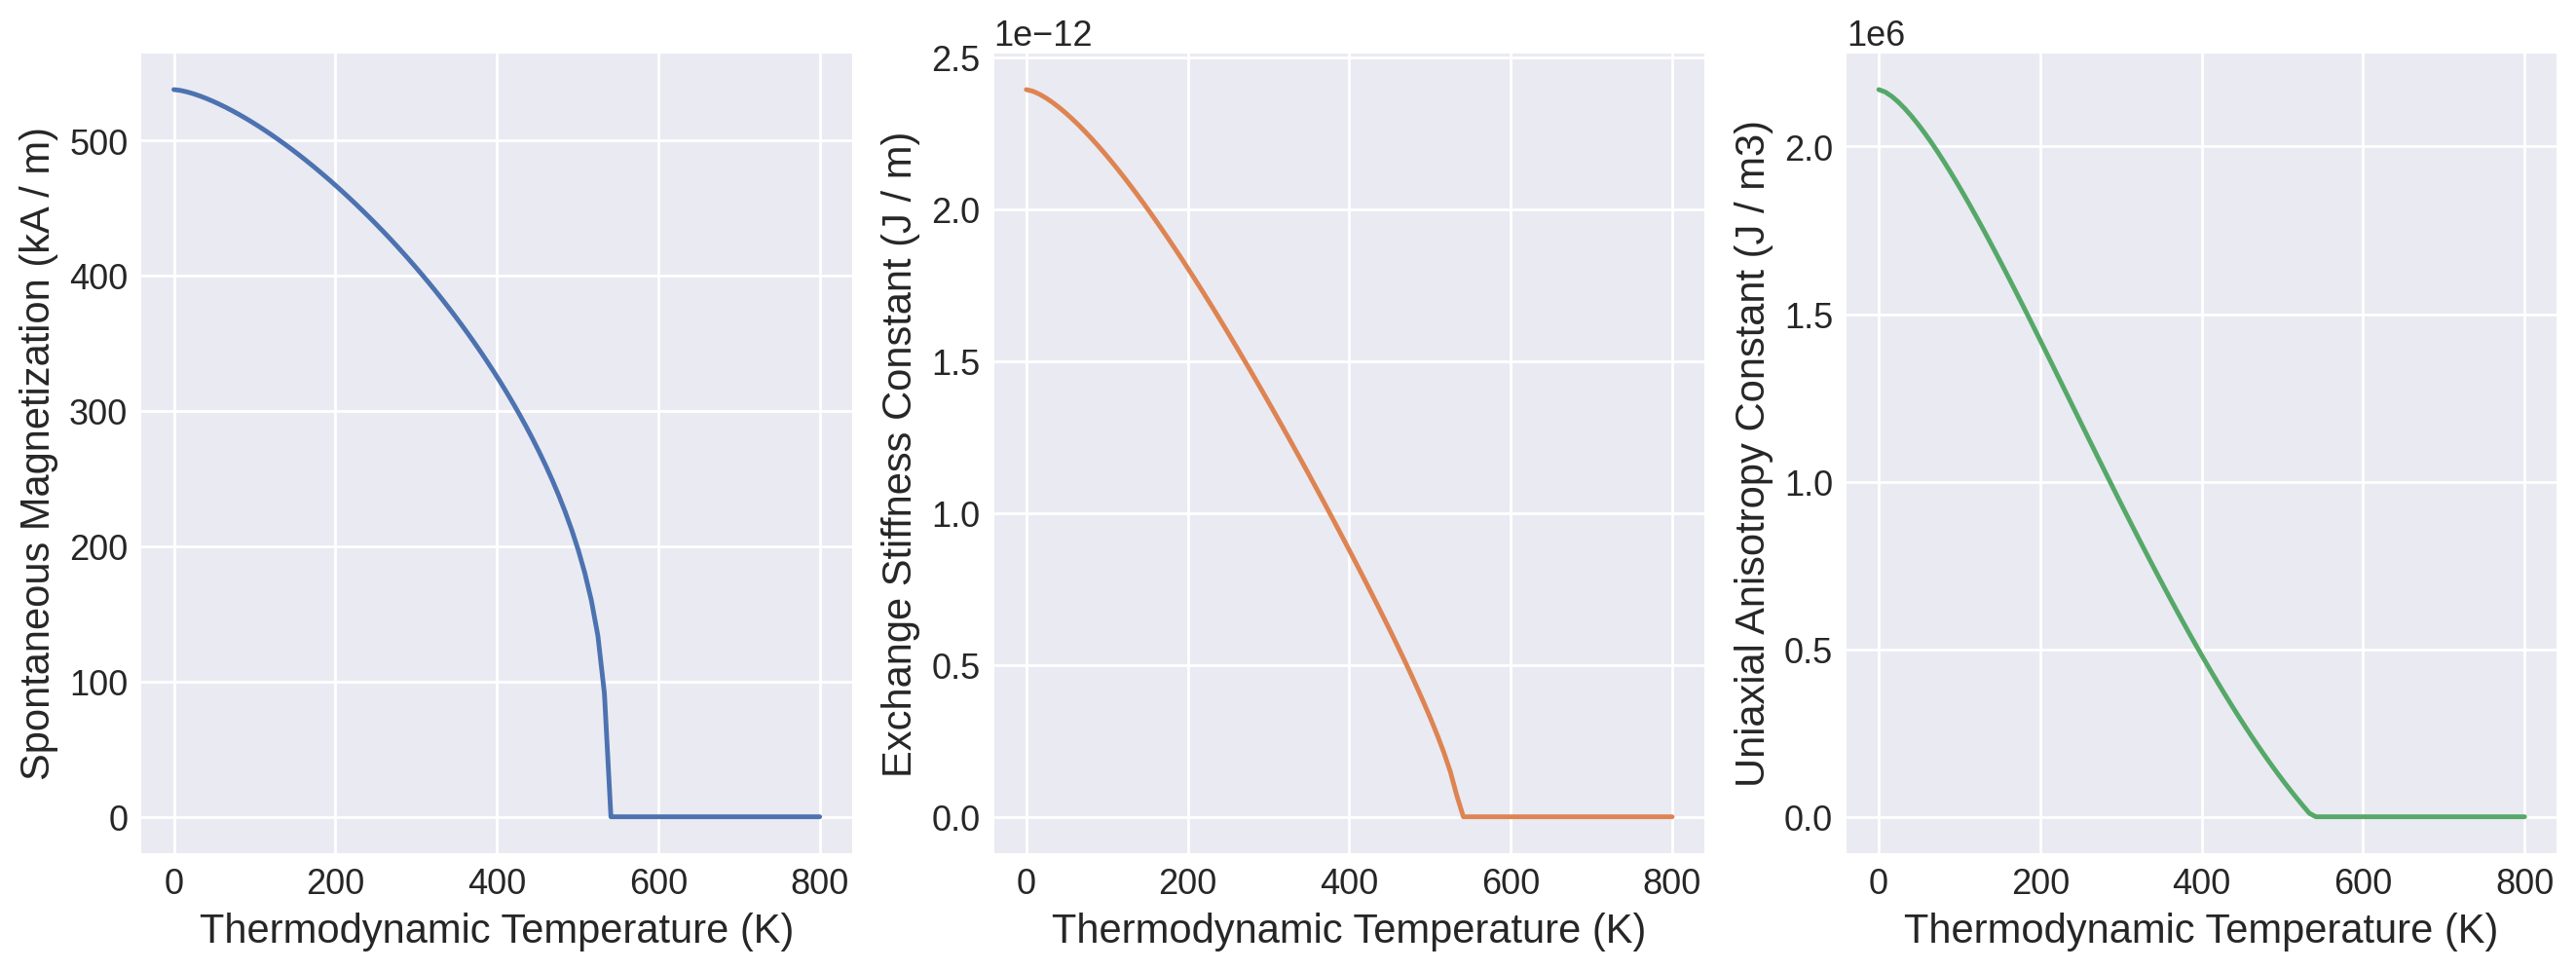

In [13]:
results_kuzmin.plot();

In [14]:
results_kuzmin

KuzminResult(Ms=Ms(T), A=A(T), Tc=Entity(ontology_label='CurieTemperature', value=537.1888739137962, unit='K'), s=<Quantity 1.82478153>, K1=K1(T))

- The attributes `Ms`, `A` and `K1` provide fit results as function of temperature. They each have a `plot` method.
- `Tc` is the fitted Curie temperature.
- `s` is a fit parameter in the Kuzmin equation.

To visually assess the accuracy of the fit, we can combine the `plot` methods of `results_kuzmin.Ms` and `results_spindynamics`:

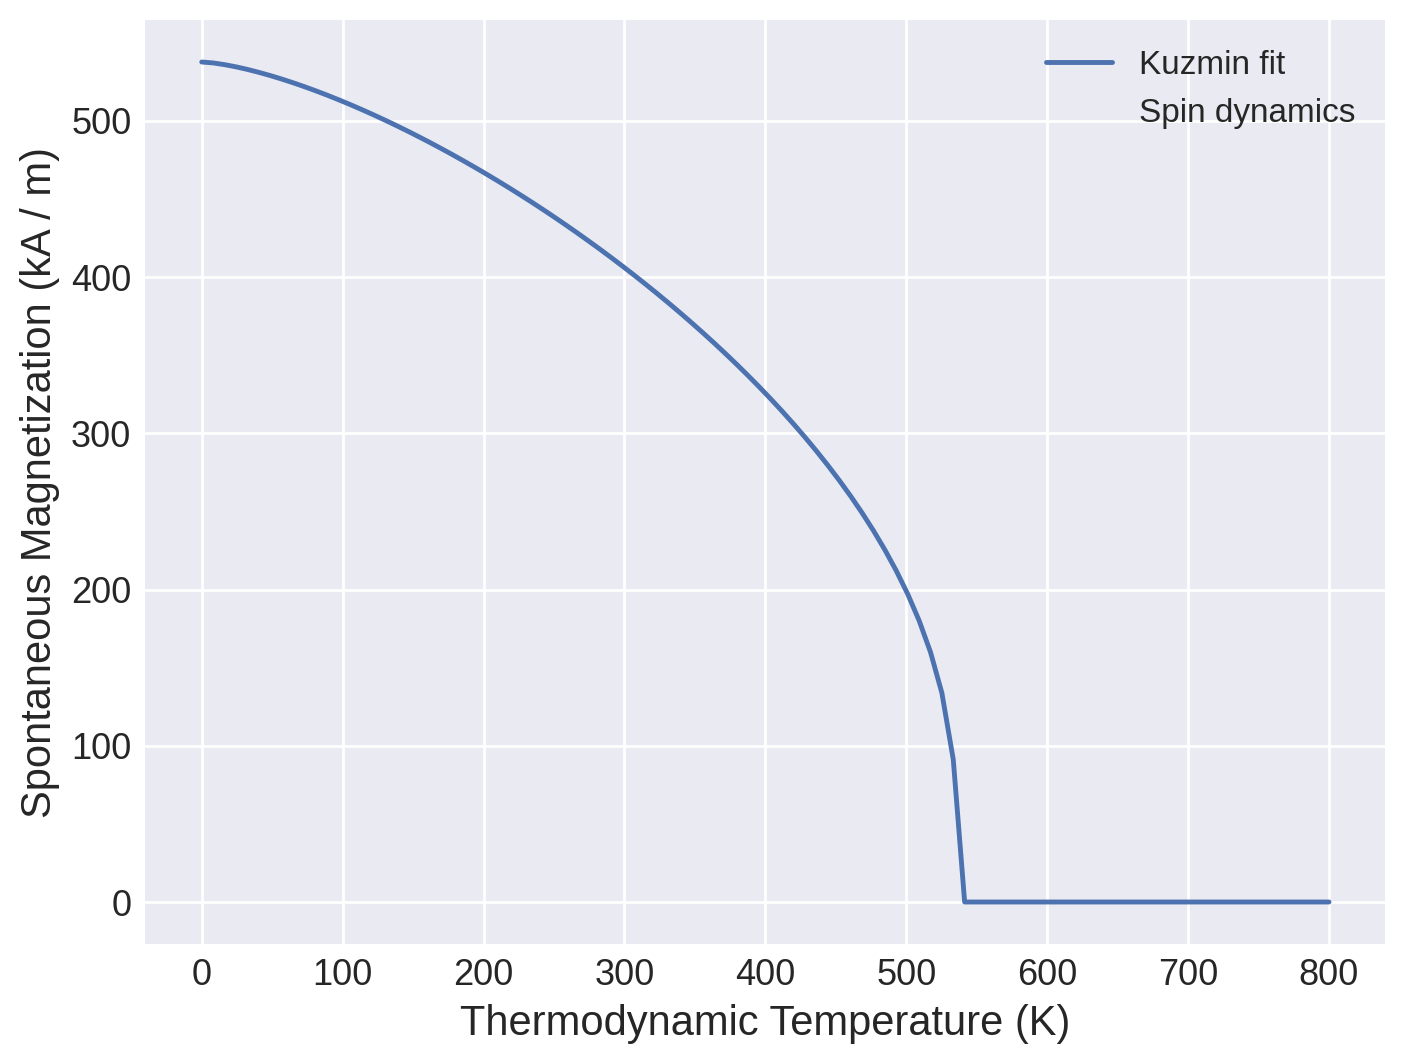

In [15]:
ax = results_kuzmin.Ms.plot(label="Kuzmin fit")
results_spindynamics.plot(ax=ax, label="Spin dynamics");

To get inputs for the micromagnetic simulation at a specific temperature we call the three attributes `Ms`, `A` and `K1`. We can pass a `mammos_entity.Entity`, an `astropy.units.Quantity` or a number:

In [16]:
temperature = me.T(300)
temperature

Entity(ontology_label='ThermodynamicTemperature', value=300.0, unit='K')

In [17]:
results_kuzmin.Ms(temperature)  # Evaluation with Entity

Entity(ontology_label='SpontaneousMagnetization', value=406.0551917707456, unit='kA / m')

In [18]:
results_kuzmin.A(300 * u.K)  # Evaluation with Quantity

Entity(ontology_label='ExchangeStiffnessConstant', value=1.3655952150453495e-12, unit='J / m')

In [19]:
results_kuzmin.K1(300)  # Evaluation with number

Entity(ontology_label='UniaxialAnisotropyConstant', value=934564.2967472294, unit='J / m3')

## Run micromagnetic simulation to compute hysteresis loop
We now compute a hysteresis loop (using a finite-element micromagnetic simulation) with the material parameters we have obtained.

First, we create the mesh of a 20x20x20 nm cube.

In [20]:
!tommos mesh --geom box --extent 20,20,20 --h 2 --out-name cube

[ok] Wrote data: cube.npz (nodes=3284, tets=15109)
[ok] Wrote visualization: cube.vtu (cell_data: mat_id)


Next, we define a micromagnetic system, specify the energy terms and define the initial magnetization as uniform (0, 0, 1).

In [21]:
system = mm.System(name="singlegrain")

In [22]:
mesh = pv.read("cube.vtu")
mesh.points *= ta.scripts.DEFAULT_MESH_UNIT
mesh.cell_data["region_id"] = mesh.cell_data.pop("mat_id")
mesh.point_data["m"] = np.tile((0.0, 0.0, 1.0), (mesh.n_points, 1))
mesh.cell_data["Ms"] = np.full(mesh.n_cells, results_kuzmin.Ms(temperature).q.to("A/m").value)
system.m = mesh.copy()

In [23]:
A = results_kuzmin.A(temperature).q.to("J/m").value
K1 = results_kuzmin.K1(temperature).q.to("J/m3").value
system.energy = mm.Exchange(A=A) + mm.UniaxialAnisotropy(K=K1, u=(0, 0, 1)) + mm.Demag()

The parameter `Hsteps` defines the field protocol: a full symmetric hysteresis loop between magnetization values corresponding to +5 Tesla and -5 Tesla in the (0, 0, 1) direction:

In [24]:
h_val = (5 * u.T).to("A/m").value
Hsteps = [
    [(0, h_val / 1e6, h_val), (0, -h_val / 1e6, -h_val), 30],
    [(0, -h_val / 1e6, -h_val), (0, h_val / 1e6, h_val), 30],
]

In [25]:
hd = ta.HysteresisDriver()
hd.drive(system, Hsteps=Hsteps)

Running Tommos (TommosRunner)[2026-10-29T18:07:44]... (18.2 s)


In [26]:
results_hysteresis = me.from_csv("singlegrain/drive-0/hyst_singlegrain/mammos_hysteresis.csv")
results_hysteresis

EntityCollection(
    description='',
    config=Entity(ontology_label='Index', value=array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12.,
           13., 14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25.,
           26., 27., 28., 29., 30., 31., 32., 33., 34., 35., 36., 37., 38.,
           39., 40., 41., 42., 43., 44., 45., 46., 47., 48., 49., 50., 51.,
           52., 53., 54., 55., 56., 57., 58.])),
    B_ext_T=Entity(ontology_label='MagneticFluxDensity', value=array([-5.        , -4.65517241, -4.31034482, -3.96551724, -3.62068965,
           -3.27586207, -2.93103448, -2.5862069 , -2.24137931, -1.89655172,
           -1.55172414, -1.20689655, -0.86206896, -0.51724138, -0.17241379,
            0.17241379,  0.51724138,  0.86206896,  1.20689655,  1.55172414,
            1.89655172,  2.24137931,  2.5862069 ,  2.93103448,  3.27586207,
            3.62068965,  3.96551724,  4.31034482,  4.65517241,  5.        ,
            4.65517241,  4.31034482,  3.96551724, 

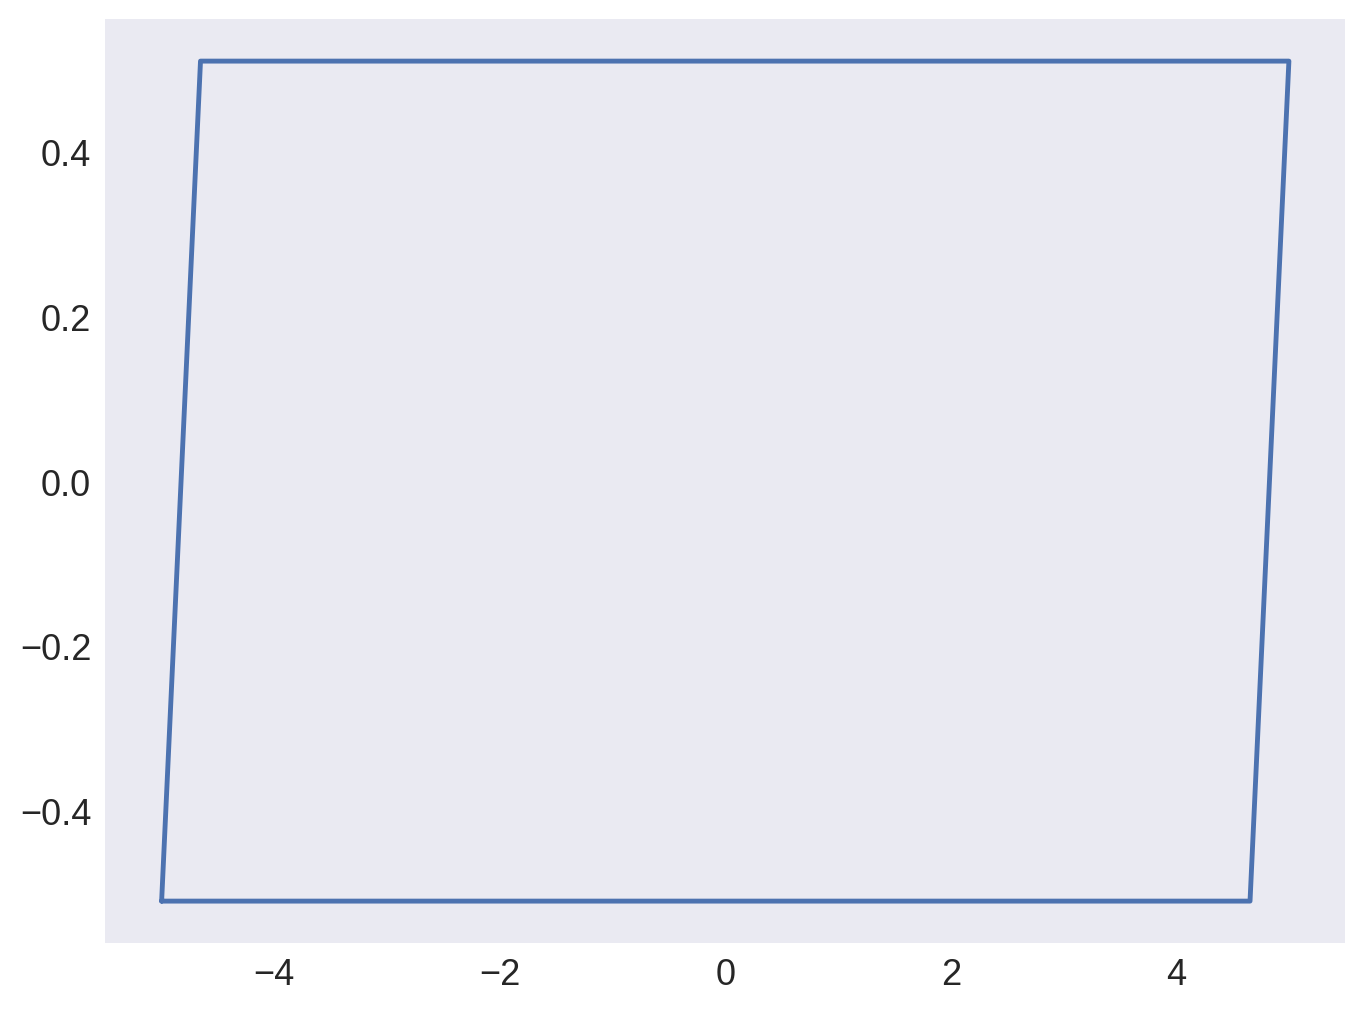

In [27]:
plt.plot(results_hysteresis.B_ext_T.value, results_hysteresis.J_par_T.value);

In [28]:
results_hysteresis["H"] = me.Entity(
    "ExternalMagneticField", results_hysteresis.B_ext_T.q.to("A/m", equivalencies=u.magnetic_flux_field())
)
results_hysteresis["M"] = me.Entity(
    "Magnetization", results_hysteresis.J_par_T.q.to("A/m", equivalencies=u.magnetic_flux_field())
)

The result object provides access to `H` and `M`:

In [29]:
results_hysteresis.H

Entity(ontology_label='ExternalMagneticField', value=array([-3978873.57274406, -3704468.49876171, -3430063.42477936,
       -3155658.35079701, -2881253.27681466, -2606848.20283231,
       -2332443.12884996, -2058038.05486762, -1783632.98088527,
       -1509227.90690292, -1234822.83292057,  -960417.75893822,
        -686012.68495587,  -411607.61097352,  -137202.53699117,
         137202.53699117,   411607.61097352,   686012.68495587,
         960417.75893822,  1234822.83292057,  1509227.90690292,
        1783632.98088527,  2058038.05486762,  2332443.12884996,
        2606848.20283231,  2881253.27681466,  3155658.35079701,
        3430063.42477936,  3704468.49876171,  3978873.57274406,
        3704468.49876171,  3430063.42477936,  3155658.35079701,
        2881253.27681466,  2606848.20283231,  2332443.12884996,
        2058038.05486762,  1783632.98088527,  1509227.90690292,
        1234822.83292057,   960417.75893822,   686012.68495587,
         411607.61097352,   137202.53699117,  -137202.53699117,
        -411607.61097352,  -686012.68495587,  -960417.75893822,
       -1234822.83292057, -1509227.90690292, -1783632.98088527,
       -2058038.05486762, -2332443.12884996, -2606848.20283231,
       -2881253.27681466, -3155658.35079701, -3430063.42477936,
       -3704468.49876171, -3978873.57274406]), unit='A / m')

In [30]:
results_hysteresis.M

Entity(ontology_label='Magnetization', value=array([-406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19157549, -406055.19157549, -406055.19157549,
       -406055.19149591, -406055.18664169,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19157549,
        406055.19157549,  406055.19157549,  406055.19149591,
        406055.18584591, -406055.19157549]), unit='A / m')

The `dataframe` property generates a dataframe in the SI units.

In [31]:
results_hysteresis.to_dataframe().head()

,config,B_ext_T,J_par_T,E,gnorm,H,M
0,0.0,-5.000000,-0.510264,-2.964840e+06,17.447159,-3.978874e+06,-406055.191575
1,1.0,-4.655172,-0.510264,-2.824821e+06,13.440620,-3.704468e+06,-406055.191575
2,2.0,-4.310345,-0.510264,-2.684802e+06,13.297850,-3.430063e+06,-406055.191575
3,3.0,-3.965517,-0.510264,-2.544783e+06,13.188117,-3.155658e+06,-406055.191575
4,4.0,-3.620690,-0.510264,-2.404764e+06,10.640769,-2.881253e+06,-406055.191575


## Analyze hysteresis loop
We can extract extrinsic properties with the `extrinsic_properties` function from the `mammos_analysis` package:

In [32]:
extrinsic_properties = mammos_analysis.hysteresis.extrinsic_properties(
    results_hysteresis.H.q[30:],  # extracting upper half-loop
    results_hysteresis.M.q[30:],  # extracting upper half-loop
    demagnetization_coefficient=1 / 3,
)

/home/pepe/repos/mammos/tommos-adapter/.pixi/envs/default/lib/python3.11/site-packages/mammos_analysis/hysteresis.py:382: UserWarning: Only 1 (H_internal, M_internal) values in second quadrant - estimate of BHmax may be inaccurate.
  warnings.warn(


In [33]:
extrinsic_properties.Hc

Entity(ontology_label='CoercivityHcExternal', value=3841671.0347848954, unit='A / m')

In [34]:
extrinsic_properties.Mr

Entity(ontology_label='Remanence', value=406055.191575492, unit='A / m')

In [35]:
extrinsic_properties.BHmax

Entity(ontology_label='MaximumEnergyProduct', value=45724.30599091787, unit='N / m2')

We can combine the `results_hysteresis.plot` method with some custom code to show Hc and Mr in the hysteresis plot:

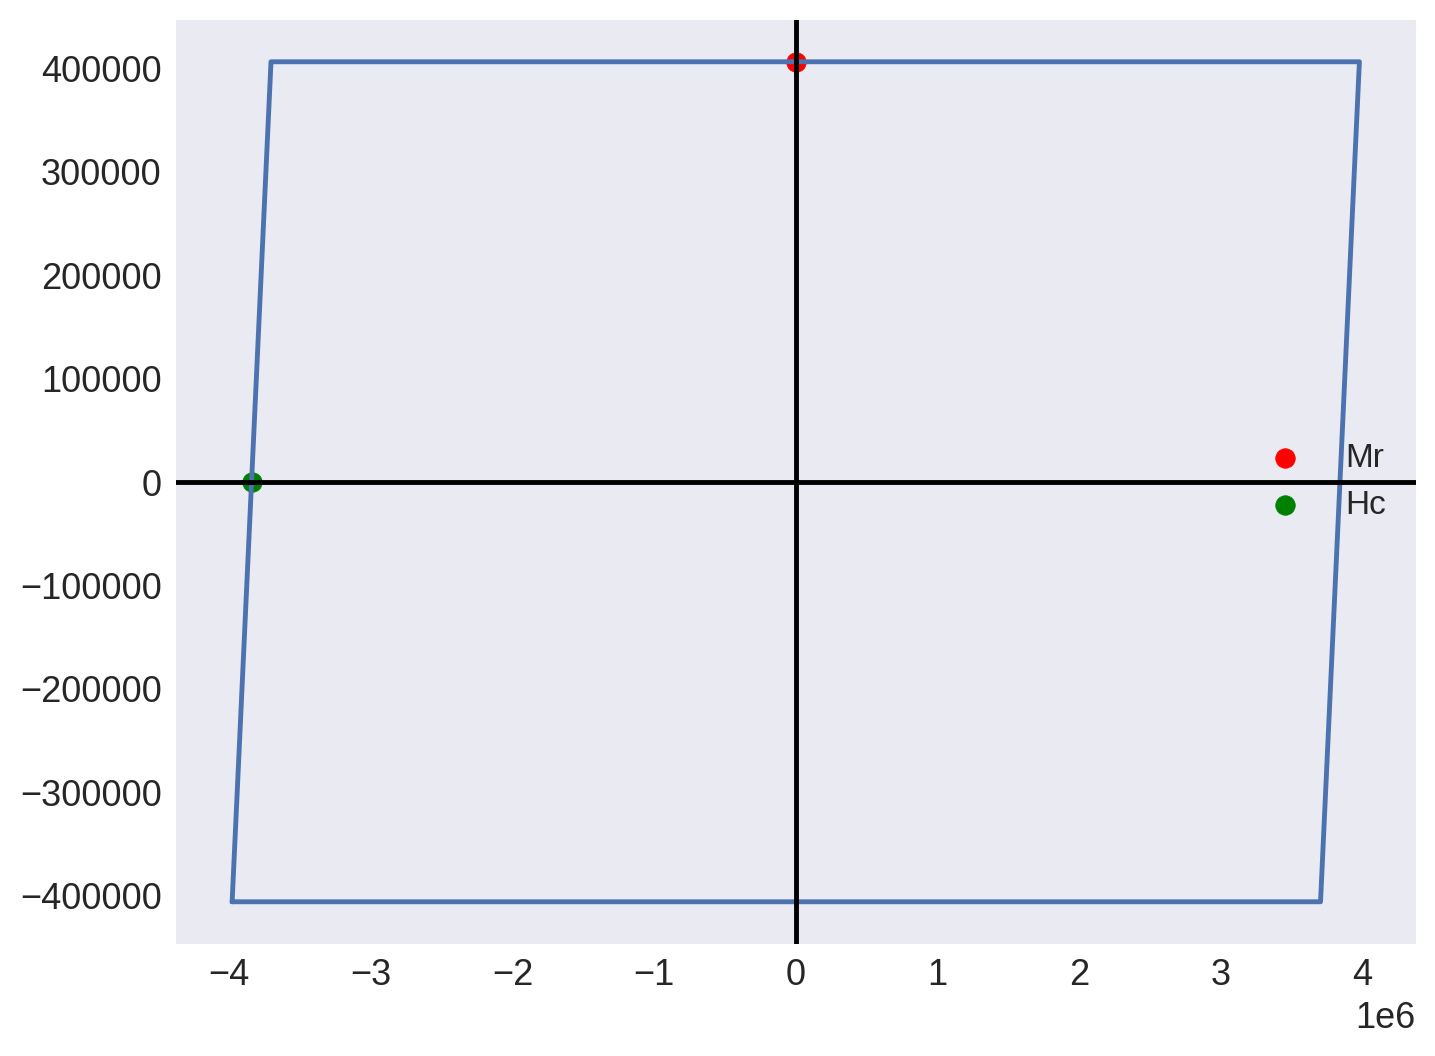

In [36]:
fig, ax = plt.subplots()
ax.plot(results_hysteresis.H.value, results_hysteresis.M.value)
ax.scatter(0, extrinsic_properties.Mr.value, c="r", label="Mr")
ax.scatter(-extrinsic_properties.Hc.value, 0, c="g", label="Hc")
ax.axhline(0, c="k")  # Horizontal line at M=0
ax.axvline(0, c="k")  # Vertical line at H=0
ax.legend();

## Compute Hc(T)

We can leverage mammos to calculate Hc(T) for multiple values of T.

First, we run hysteresis simulations at 7 different temperatures and collect all simulation results:

In [37]:
T = np.linspace(0, 1.1 * results_kuzmin.Tc.q, 7)
h_val = (9 * u.T).to("A/m").value
Hsteps = [
    [(0, h_val / 1e6, h_val), (0, -h_val / 1e6, -h_val), 30],
    [(0, -h_val / 1e6, -h_val), (0, h_val / 1e6, h_val), 30],
]

simulations = []
for i, temperature in enumerate(T):
    print(f"Running simulation for T={temperature:.0f}")
    system.m.point_data["m"] = np.tile((0.0, 0.0, 1.0), (mesh.n_points, 1))
    system.m.cell_data["Ms"] = np.full(mesh.n_cells, results_kuzmin.Ms(temperature).q.to("A/m").value)
    system.energy = (
        mm.Exchange(A=results_kuzmin.A(temperature).q.to("J/m").value)
        + mm.UniaxialAnisotropy(K=results_kuzmin.K1(temperature).q.to("J/m3").value, u=(0, 0, 1))
        + mm.Demag()
    )
    hd.drive(system, Hsteps=Hsteps)
    results_hysteresis = me.from_csv(f"singlegrain/drive-{i + 1}/hyst_singlegrain/mammos_hysteresis.csv")
    simulations.append(results_hysteresis)

Running simulation for T=0 K
Running Tommos (TommosRunner)[2026-10-29T18:08:02]... (18.2 s)
Running simulation for T=98 K
Running Tommos (TommosRunner)[2026-10-29T18:08:21]... (15.8 s)
Running simulation for T=197 K
Running Tommos (TommosRunner)[2026-10-29T18:08:36]... (15.9 s)
Running simulation for T=295 K
Running Tommos (TommosRunner)[2026-10-29T18:08:52]... (15.6 s)
Running simulation for T=394 K
Running Tommos (TommosRunner)[2026-10-29T18:09:08]... (16.6 s)
Running simulation for T=492 K
Running Tommos (TommosRunner)[2026-10-29T18:09:25]... (16.1 s)
Running simulation for T=591 K
Running Tommos (TommosRunner)[2026-10-29T18:09:41]... (9.5 s)


In [38]:
Hcs = []
for res in simulations:
    res.H = me.Entity("ExternalMagneticField", res.B_ext_T.q.to("A/m", equivalencies=u.magnetic_flux_field()))
    res.M = me.Entity("Magnetization", res.J_par_T.q.to("A/m", equivalencies=u.magnetic_flux_field()))
    cf = mammos_analysis.hysteresis.extract_coercive_field(H=res.H.q[30:], M=res.M.q[30:]).value
    if np.isnan(cf):  # Above Tc
        cf = 0
    Hcs.append(cf)

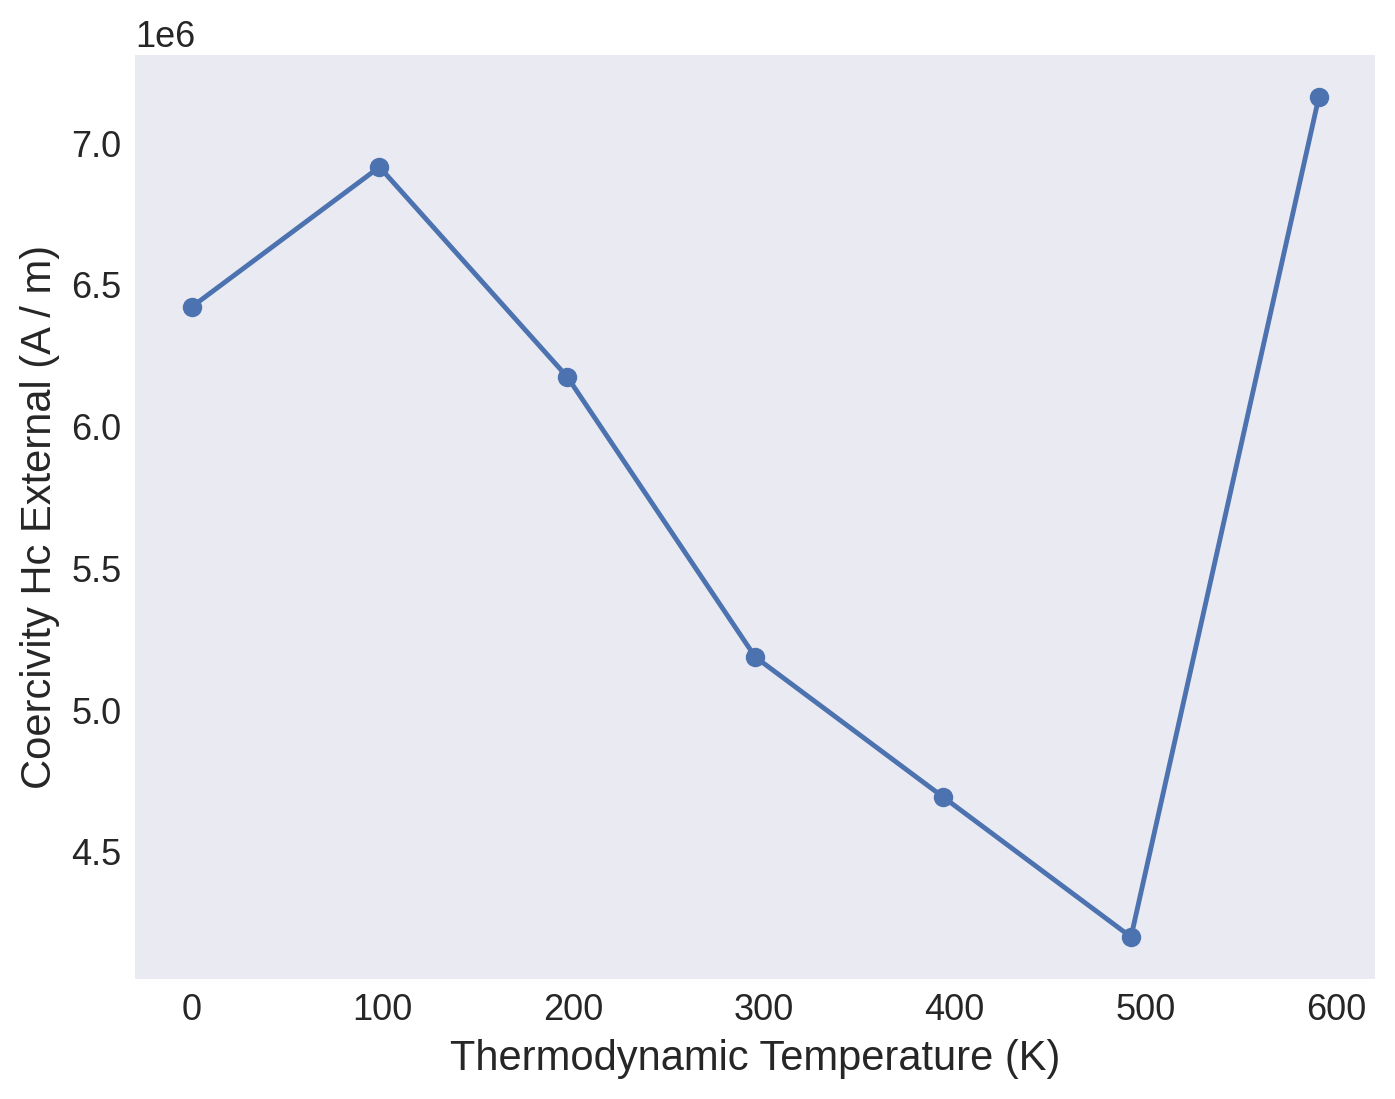

In [39]:
plt.plot(T, Hcs, linestyle="-", marker="o")
plt.xlabel(me.T().axis_label)
plt.ylabel(me.Hc().axis_label);

We can also show the hysteresis loops of all simulations:

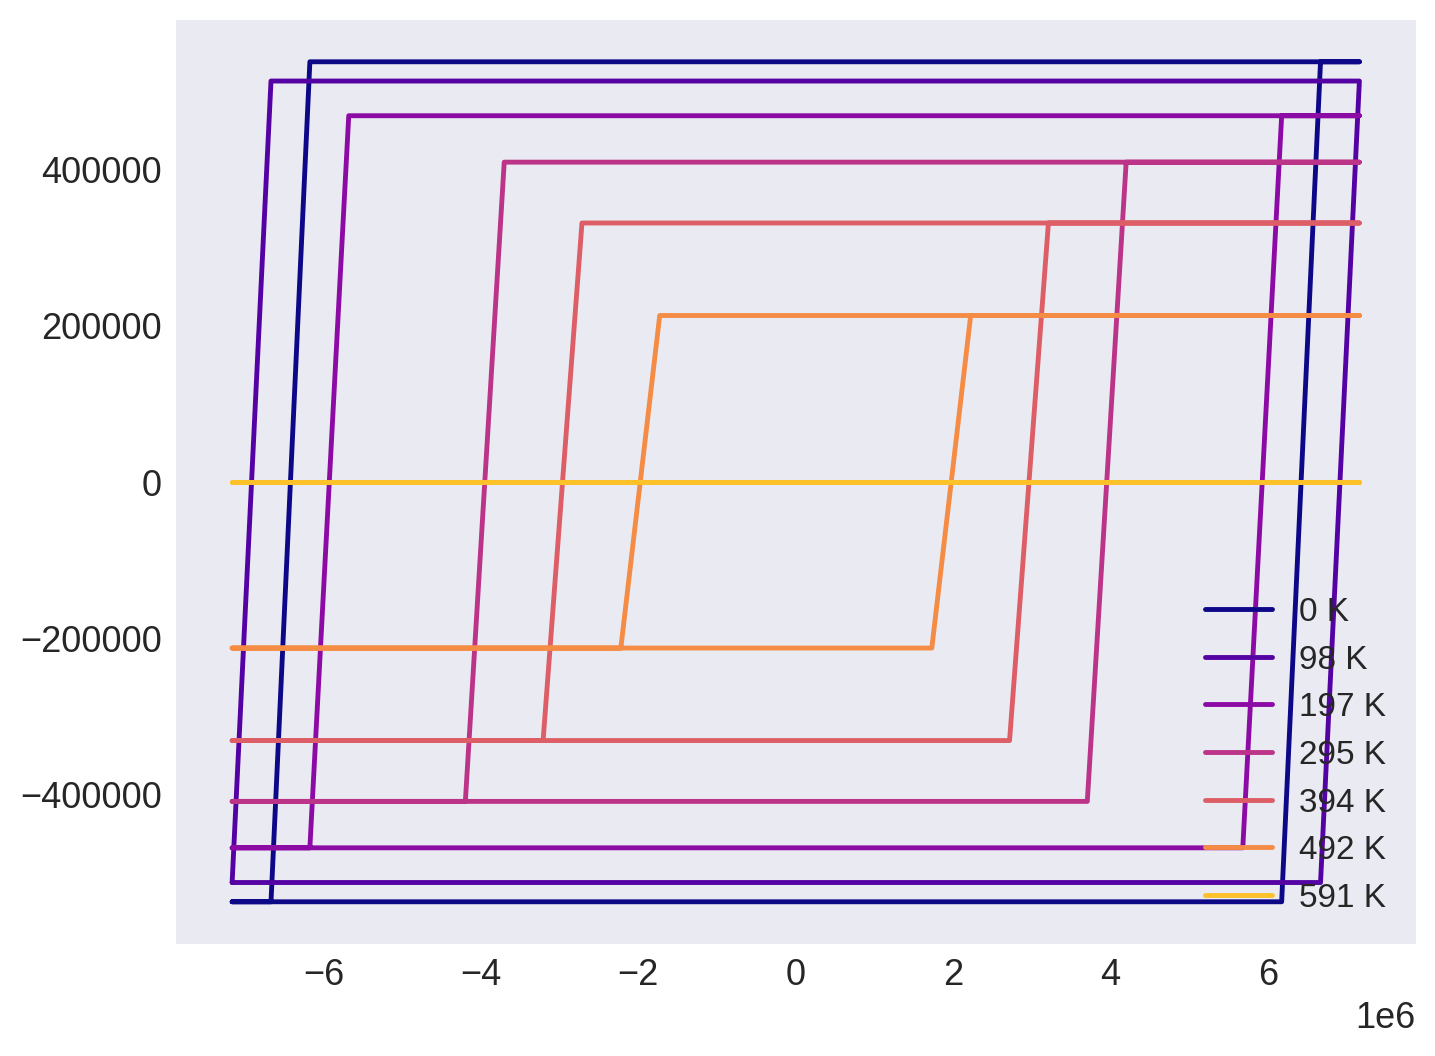

In [40]:
colors = colormaps["plasma"].colors[:: math.ceil(256 / len(T))]

fix, ax = plt.subplots()
for temperature, sim, color in zip(T, simulations, colors, strict=False):
    if np.isnan(sim.M.q).all():  # no Ms above Tc
        continue
    ax.plot(sim.H.value, sim.M.value, label=f"{temperature:.0f}", color=color)
ax.legend(loc="lower right");